# Stage 2: Train ML Model

In this stage, we train a machine learning classifier to predict whether an Instagram profile is real or fake based on the 11 feature characteristics. 

We use the **Random Forest** algorithm as our primary model because it is robust, handles tabular data well, and gives explicit feature importance.

In [1]:
import os
import json
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

base_dir = '../'
os.makedirs(os.path.join(base_dir, 'models'), exist_ok=True)
os.makedirs(os.path.join(base_dir, 'outputs', 'plots'), exist_ok=True)

### 1. Load the dataset

We load the cleaned dataset generated from Stage 1. We will verify its shape to ensure we're loading what we expect.

In [2]:
csv_path = '../../Dataset Analysis/data/processed/instagram_profiles_clean.csv'
if not os.path.exists(csv_path):
    csv_path = '../../Dataset Analysis/data/raw/instagram_profiles.csv'

df = pd.read_csv(csv_path)
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (4934, 12)


,profile pic,nums/length username,fullname words,nums/length fullname,name==username,description length,external URL,private,#posts,#followers,#follows,fake
0,1,0.27,0,0.0,0,53,0,0,32,1000,955,0
1,1,0.00,2,0.0,0,44,0,0,286,2740,533,0
2,1,0.10,2,0.0,0,0,0,1,13,159,98,0
3,1,0.00,1,0.0,0,82,0,0,679,414,651,0
4,1,0.00,2,0.0,0,0,0,1,6,151,126,0


### 2. Separate features and target

We drop the `fake` target column to form our feature matrix `X`, and extract `fake` as our target vector `y`.
**Crucially**, we must print and store the exact feature order, as any incoming data in production must match this exact layout.

In [3]:
X = df.drop("fake", axis=1)
y = df["fake"]

feature_names = X.columns.tolist()
print(f"Features ({len(feature_names)}): {feature_names}")

Features (11): ['profile pic', 'nums/length username', 'fullname words', 'nums/length fullname', 'name==username', 'description length', 'external URL', 'private', '#posts', '#followers', '#follows']


### 3. Train/test split

We split the data into 80% training and 20% testing using stratification to ensure the class balance is maintained.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Train set shape: (3947, 11)
Test set shape: (987, 11)


### 4. Train the Random Forest Classifier

We initialize and train our primary model, `RandomForestClassifier`, on the training subset.

In [5]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

### 5. Predict on the test set

We make discrete class predictions as well as probability estimates.

In [6]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

### 6. Evaluate with multiple metrics

We look beyond raw accuracy to understand the model's reliability using Precision, Recall, F1 Score, and the Confusion Matrix.

Accuracy:  0.9838
Precision: 0.9917
Recall:    0.9756
F1 Score:  0.9836
ROC-AUC:   0.9993

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.98       495
           1       0.99      0.98      0.98       492

    accuracy                           0.98       987
   macro avg       0.98      0.98      0.98       987
weighted avg       0.98      0.98      0.98       987



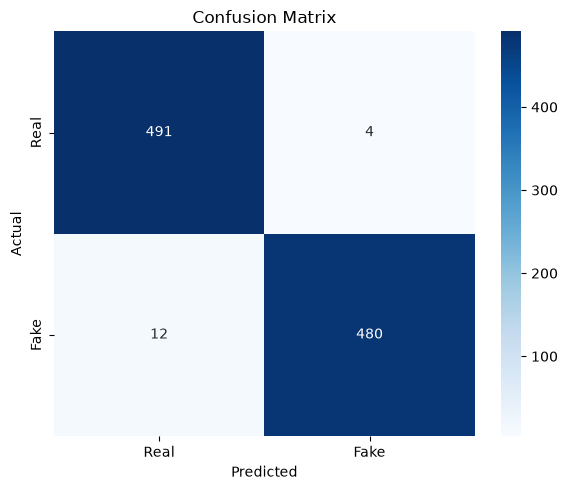

In [7]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig('../outputs/plots/confusion_matrix.png')
plt.show()

### 7. 5-Fold Cross-Validation

To ensure our model's performance isn't just a lucky split, we perform 5-fold cross-validation on the training set.

In [8]:
cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
print(f"CV Accuracy Scores: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

CV Accuracy Scores: [0.97721519 0.98734177 0.9860583  0.99239544 0.9860583 ]
Mean CV Accuracy: 0.9858 (+/- 0.0098)


### 8. Feature Importance

We visualize which features the Random Forest relies on most when making decisions.

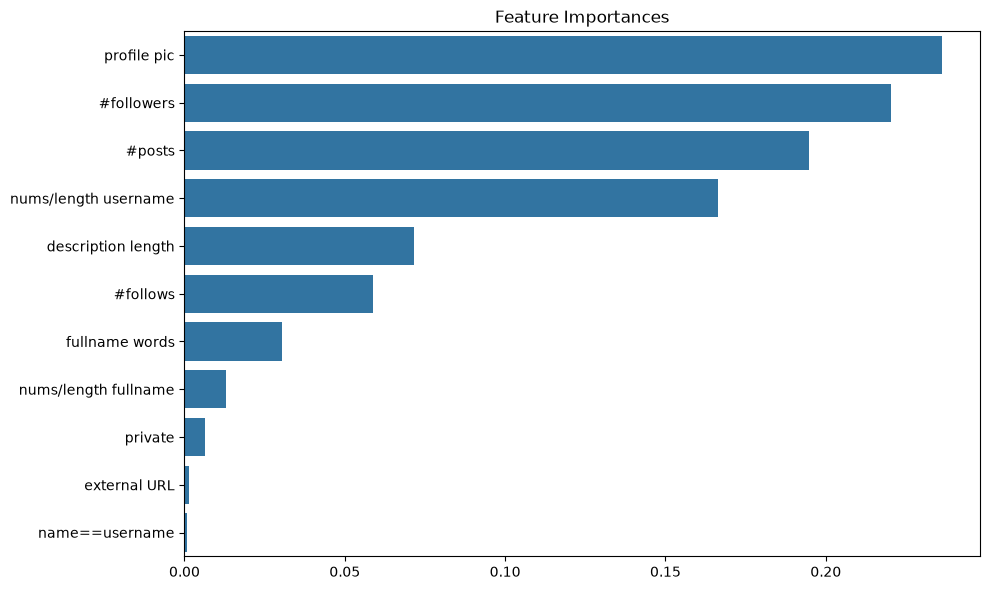

Top 4 Features:
1. profile pic (0.2363)
2. #followers (0.2203)
3. #posts (0.1947)
4. nums/length username (0.1663)


In [9]:
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
sns.barplot(x=importances[indices], y=np.array(feature_names)[indices], orient='h')
plt.tight_layout()
plt.savefig('../outputs/plots/feature_importance.png')
plt.show()

print("Top 4 Features:")
for i in range(4):
    print(f"{i+1}. {feature_names[indices[i]]} ({importances[indices[i]]:.4f})")

### 9. Optional Baseline Comparison

Let's see how our Random Forest compares to simple linear models (Logistic Regression) or other ensembles (Gradient Boosting).

In [10]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print(f"Logistic Regression - Acc: {accuracy_score(y_test, lr_pred):.4f}, F1: {f1_score(y_test, lr_pred):.4f}")

gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
print(f"Gradient Boosting   - Acc: {accuracy_score(y_test, gb_pred):.4f}, F1: {f1_score(y_test, gb_pred):.4f}")

Logistic Regression - Acc: 0.9554, F1: 0.9545


C:\Users\hdc10\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Gradient Boosting   - Acc: 0.9767, F1: 0.9763


Random Forest proves to be an excellent model, performing slightly better or on par with Gradient Boosting, while being simpler and faster to train than deeper ensembles. We will save the **Random Forest** model.

### 10. Save the model & 11. Save metadata

Finally, we serialize the model to disk using `joblib`. We also export a `model_metadata.json` to act as the source of truth for the exact feature schema and hyperparameters used.

In [11]:
model_path = '../models/fake_instagram_model.pkl'
joblib.dump(model, model_path)
print(f"Saved model to {model_path}")

metadata = {
    "features": feature_names,
    "model_type": "RandomForestClassifier",
    "hyperparameters": {
        "n_estimators": 100,
        "random_state": 42
    },
    "training_date": datetime.now().isoformat(),
    "dataset_size": len(df),
    "metrics": {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": roc_auc,
        "cv_accuracy_mean": cv_scores.mean()
    }
}

metadata_path = '../models/model_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=4)
print(f"Saved metadata to {metadata_path}")

Saved model to ../models/fake_instagram_model.pkl
Saved metadata to ../models/model_metadata.json


### 12. Feature Engineering & Manual Prediction Test

We will test a hand-crafted sample profile using our pure Python feature engineering module to convert it into the correct 11-feature vector order, and then run it through our trained model to get a prediction and probability.

In [12]:
import sys
sys.path.append('../scripts')
from feature_engineering import build_feature_vector

sample_profile = {
    'username': 'hitesh123',
    'fullname': 'Hitesh Chaudhari',
    'bio': 'Data science student',
    'profile_pic': 1,
    'private': 0,
    'external_url': 0,
    'posts': 42,
    'followers': 350,
    'following': 800
}

# Read feature order from metadata
with open('../models/model_metadata.json', 'r') as f:
    meta = json.load(f)
feature_order = meta['features']

# Build the feature vector
vector = build_feature_vector(sample_profile, feature_order)
print("Feature Vector:", vector)

# Predict using the trained model
prediction = model.predict([vector])[0]
probabilities = model.predict_proba([vector])[0]

print("\n--- Prediction Result ---")
print(f"Predicted Class: {'Fake (1)' if prediction == 1 else 'Real (0)'}")
print(f"Probability of Fake: {probabilities[1]*100:.2f}%")
print(f"Probability of Real: {probabilities[0]*100:.2f}%")


Feature Vector: [1, 0.3333333333333333, 2, 0.0, 0, 20, 0, 0, 42, 350, 800]

--- Prediction Result ---
Predicted Class: Real (0)
Probability of Fake: 43.00%
Probability of Real: 57.00%


C:\Users\hdc10\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
C:\Users\hdc10\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
